<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-11-DeepLabV3-Mask-RCNN-Segmentation/DL_Tutorial_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import random
import os

from PIL import Image
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from torchvision.models.segmentation import (
    deeplabv3_resnet101,
    DeepLabV3_ResNet101_Weights
)

from torch.utils.data import Dataset, Subset
from sklearn.model_selection import train_test_split

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda


In [2]:
weights = DeepLabV3_ResNet101_Weights.DEFAULT

deeplab_model = deeplabv3_resnet101(
    weights=weights
).to(device)

deeplab_model.eval()

class_names = weights.meta["categories"]

print("Total classes:", len(class_names))
print("Classes:", class_names)

print("Cat class ID:", class_names.index("cat"))
print("Dog class ID:", class_names.index("dog"))

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet101_coco-586e9e4e.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet101_coco-586e9e4e.pth


100%|██████████| 233M/233M [00:02<00:00, 94.7MB/s]


Total classes: 21
Classes: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
Cat class ID: 8
Dog class ID: 12


100%|██████████| 792M/792M [00:32<00:00, 24.7MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.0MB/s]


Original image: (394, 500)


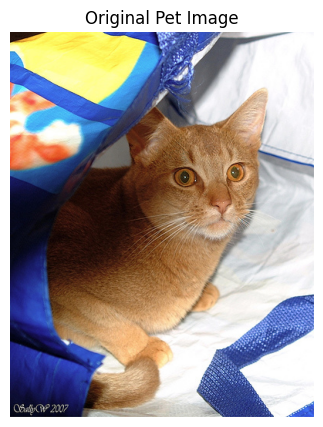

In [3]:
raw_dataset = OxfordIIITPet(
    root="/content/pet_data",
    split="trainval",
    target_types="segmentation",
    download=True
)

image, original_mask = raw_dataset[0]

image = image.convert("RGB")

print("Original image:", image.size)

plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Original Pet Image")
plt.axis("off")
plt.show()

In [4]:
preprocess = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

input_tensor = preprocess(image).unsqueeze(0).to(device)

print("Input shape:", input_tensor.shape)

Input shape: torch.Size([1, 3, 320, 320])


In [5]:
deeplab_model.eval()

with torch.inference_mode():

    output = deeplab_model(input_tensor)["out"]

    prediction = output.argmax(dim=1)[0]

prediction = prediction.cpu().numpy()

print("Output tensor:", output.shape)
print("Predicted mask:", prediction.shape)
print("Predicted class IDs:", np.unique(prediction))

Output tensor: torch.Size([1, 21, 320, 320])
Predicted mask: (320, 320)
Predicted class IDs: [0 8]


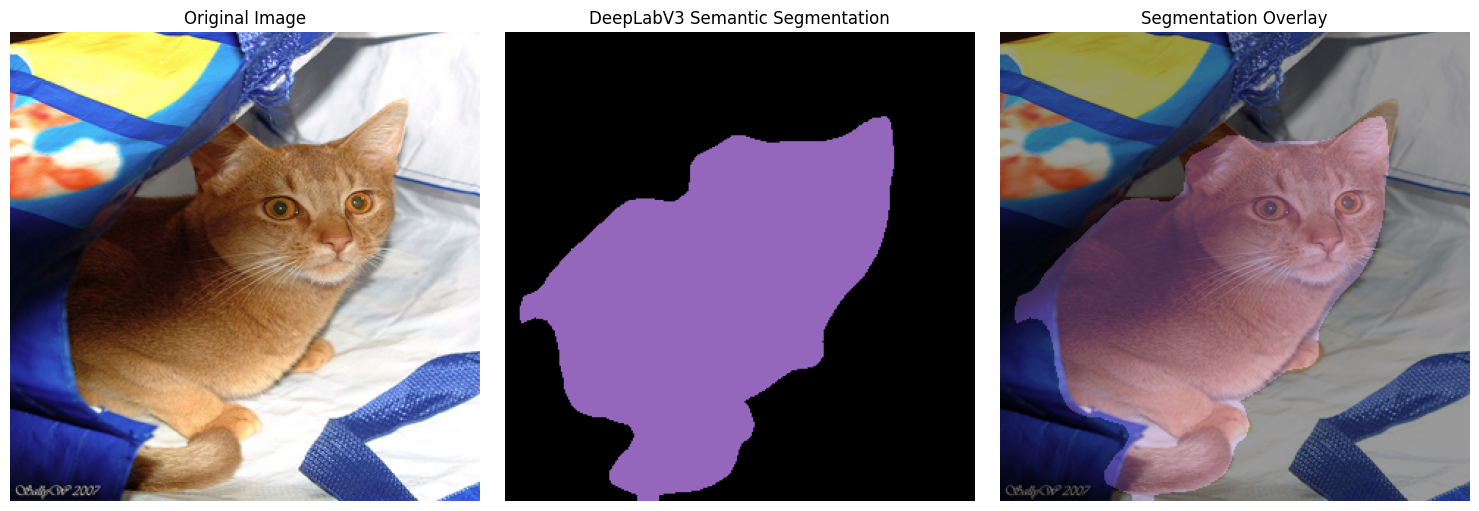

In [6]:
from matplotlib import colormaps

num_classes = len(class_names)

# Fixed color palette
palette = (
    colormaps["tab20"](
        np.linspace(0, 1, num_classes)
    )[:, :3] * 255
).astype(np.uint8)

# Background is black
palette[0] = [0, 0, 0]

segmentation_map = palette[prediction]

image_resized = image.resize((320, 320))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_resized)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(segmentation_map)
plt.title("DeepLabV3 Semantic Segmentation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image_resized)
plt.imshow(
    segmentation_map,
    alpha=0.4
)
plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
class PetSegmentationDataset(Dataset):

    def __init__(self, base_dataset, indices, size=128):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.size = size

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):

        image, mask = self.base_dataset[self.indices[idx]]
        image = image.convert("RGB")

        image = TF.resize(
            image, [self.size, self.size],
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask, [self.size, self.size],
            interpolation=InterpolationMode.NEAREST
        )

        image_tensor = TF.to_tensor(image)

        # Same mask convention as Tutorial 10:
        # 1 and 3 = pet foreground; 2 = background
        mask_array = np.array(mask)
        binary_mask = (mask_array != 2).astype(np.float32)

        mask_tensor = torch.from_numpy(
            binary_mask
        ).unsqueeze(0)

        return image_tensor, mask_tensor


# Recreate Tutorial 10 selection
rng = np.random.RandomState(42)

selected_indices = rng.choice(
    len(raw_dataset),
    size=150,
    replace=False
).tolist()

pet_dataset = PetSegmentationDataset(
    raw_dataset,
    selected_indices,
    size=128
)

all_indices = list(range(150))

train_indices, remaining_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42
)

val_indices, test_indices = train_test_split(
    remaining_indices,
    test_size=0.50,
    random_state=42
)

pet_test_dataset = Subset(
    pet_dataset,
    test_indices
)

print("Training:", len(train_indices))
print("Validation:", len(val_indices))
print("Testing:", len(pet_test_dataset))

Training: 105
Validation: 22
Testing: 23


In [8]:
def calculate_metrics(pred_mask, true_mask):

    pred_mask = np.asarray(pred_mask).astype(bool)
    true_mask = np.asarray(true_mask).astype(bool)

    intersection = np.logical_and(
        pred_mask, true_mask
    ).sum()

    union = np.logical_or(
        pred_mask, true_mask
    ).sum()

    pred_pixels = pred_mask.sum()
    true_pixels = true_mask.sum()

    dice = (
        2 * intersection / (pred_pixels + true_pixels)
        if pred_pixels + true_pixels > 0
        else 1.0
    )

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    accuracy = (pred_mask == true_mask).mean()

    return accuracy, dice, iou

In [9]:
import torch.nn.functional as F

cat_id = class_names.index("cat")
dog_id = class_names.index("dog")

deeplab_results = []
deeplab_predictions = {}

deeplab_model.eval()

for idx in range(len(pet_test_dataset)):

    image_tensor, true_mask = pet_test_dataset[idx]

    image_pil = TF.to_pil_image(image_tensor)

    model_input = preprocess(
        image_pil
    ).unsqueeze(0).to(device)

    with torch.inference_mode():

        logits = deeplab_model(model_input)["out"]

        # Resize class logits back to mask resolution
        logits = F.interpolate(
            logits,
            size=true_mask.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        predicted_classes = logits.argmax(
            dim=1
        )[0].cpu().numpy()

    pred_mask = np.isin(
        predicted_classes,
        [cat_id, dog_id]
    )

    gt_mask = true_mask.squeeze().numpy()

    accuracy, dice, iou = calculate_metrics(
        pred_mask,
        gt_mask
    )

    deeplab_results.append({
        "Image": idx,
        "Pixel Accuracy": accuracy,
        "Dice": dice,
        "IoU": iou
    })

    deeplab_predictions[idx] = pred_mask


deeplab_df = pd.DataFrame(deeplab_results)

print("DeepLabV3 Test Results")
display(deeplab_df.describe().loc[["mean"]])

DeepLabV3 Test Results


,Image,Pixel Accuracy,Dice,IoU
mean,11.0,0.934483,0.865393,0.801839


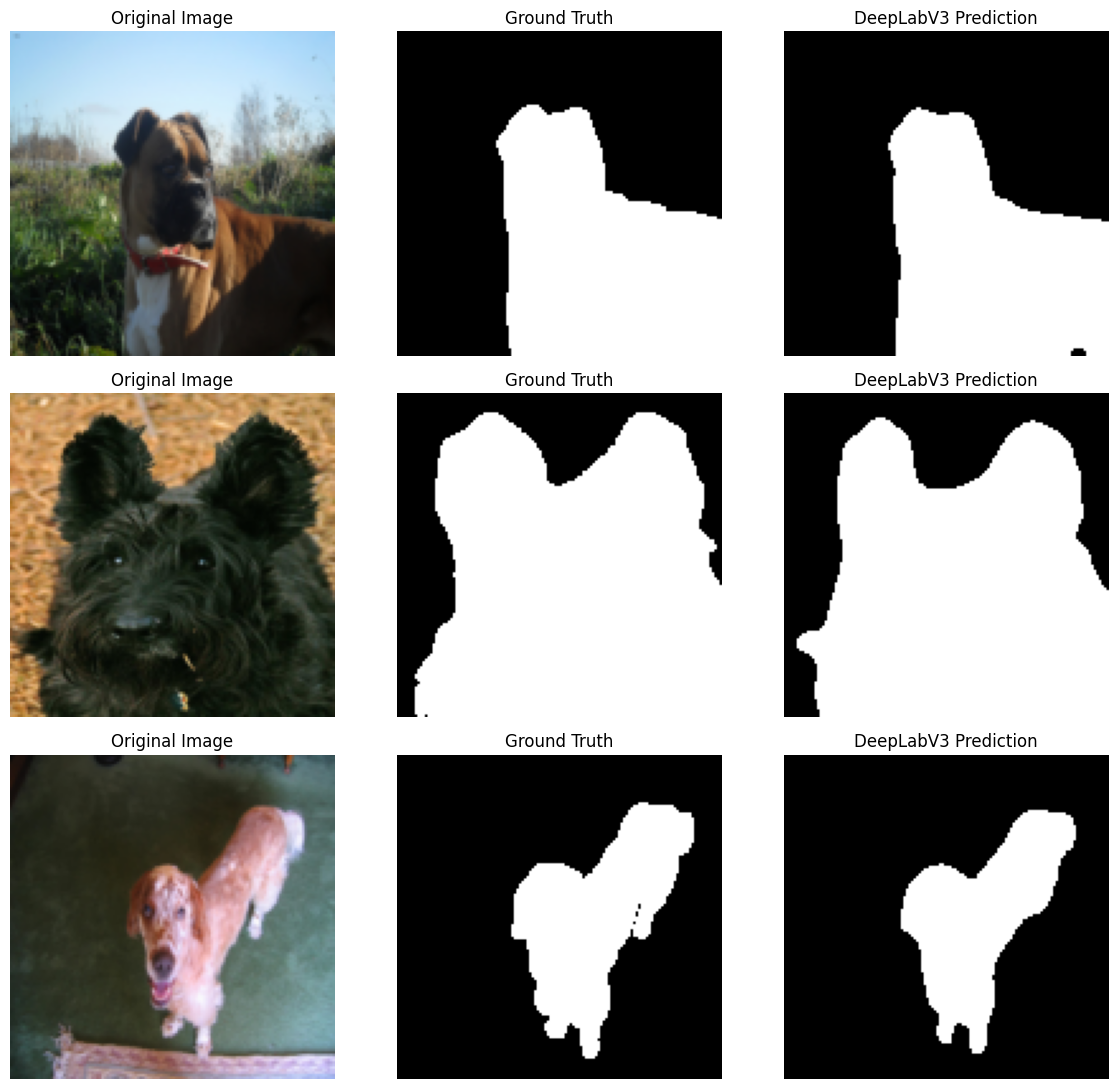

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(12, 11))

for i in range(3):

    image, true_mask = pet_test_dataset[i]

    axes[i, 0].imshow(
        image.permute(1, 2, 0).numpy()
    )
    axes[i, 0].set_title("Original Image")

    axes[i, 1].imshow(
        true_mask.squeeze().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(
        deeplab_predictions[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("DeepLabV3 Prediction")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [11]:
from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)

mask_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

mask_rcnn = maskrcnn_resnet50_fpn(
    weights=mask_weights,
    min_size=256,
    max_size=512
).to(device)

mask_rcnn.eval()

coco_classes = mask_weights.meta["categories"]

cat_coco_id = coco_classes.index("cat")
dog_coco_id = coco_classes.index("dog")

print("Mask R-CNN loaded")
print("Cat class:", cat_coco_id)
print("Dog class:", dog_coco_id)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 144MB/s]


Mask R-CNN loaded
Cat class: 17
Dog class: 18


In [12]:
image, true_mask = pet_test_dataset[0]

with torch.inference_mode():

    prediction = mask_rcnn(
        [image.to(device)]
    )[0]

print("Bounding boxes:", prediction["boxes"].shape)
print("Class labels:", prediction["labels"].shape)
print("Scores:", prediction["scores"].shape)
print("Masks:", prediction["masks"].shape)

Bounding boxes: torch.Size([4, 4])
Class labels: torch.Size([4])
Scores: torch.Size([4])
Masks: torch.Size([4, 1, 128, 128])


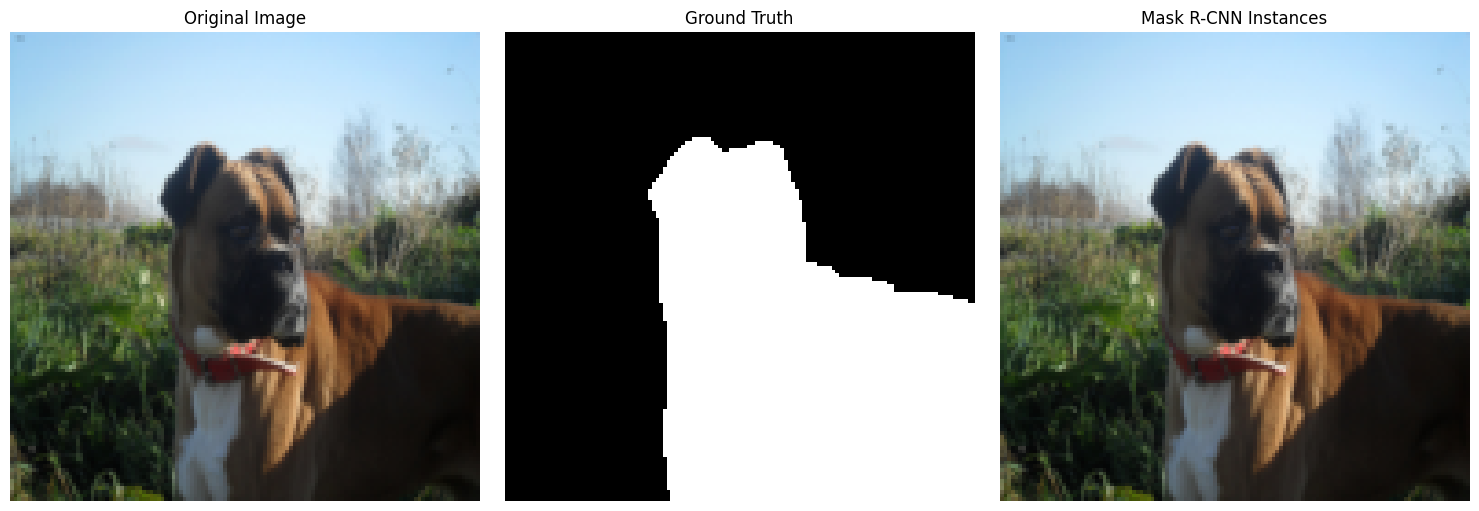

In [13]:
import matplotlib.patches as patches

confidence_threshold = 0.5
mask_threshold = 0.5

image_np = image.permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image_np)
axes[0].set_title("Original Image")

axes[1].imshow(
    true_mask.squeeze().numpy(),
    cmap="gray",
    vmin=0,
    vmax=1
)
axes[1].set_title("Ground Truth")

axes[2].imshow(image_np)
axes[2].set_title("Mask R-CNN Instances")

for box, label, score, mask in zip(
    prediction["boxes"].cpu(),
    prediction["labels"].cpu(),
    prediction["scores"].cpu(),
    prediction["masks"].cpu()
):

    if score.item() < confidence_threshold:
        continue

    if label.item() not in [cat_coco_id, dog_coco_id]:
        continue

    x1, y1, x2, y2 = box.numpy()

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )

    axes[2].add_patch(rectangle)

    binary_mask = mask[0].numpy() >= mask_threshold

    overlay = np.zeros(
        (*binary_mask.shape, 4),
        dtype=np.float32
    )

    overlay[..., 1] = 1.0
    overlay[..., 3] = binary_mask.astype(float) * 0.4

    axes[2].imshow(overlay)

    axes[2].text(
        x1, y1,
        f"{coco_classes[label.item()]} {score:.2f}",
        color="white",
        bbox={"facecolor": "green", "alpha": 0.7}
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
maskrcnn_results = []
maskrcnn_predictions = {}

mask_rcnn.eval()

for idx in range(len(pet_test_dataset)):

    image, true_mask = pet_test_dataset[idx]

    with torch.inference_mode():

        prediction = mask_rcnn(
            [image.to(device)]
        )[0]

    scores = prediction["scores"].cpu()
    labels = prediction["labels"].cpu()
    masks_pred = prediction["masks"].cpu()

    valid = (
        (scores >= 0.5) &
        (
            (labels == cat_coco_id) |
            (labels == dog_coco_id)
        )
    )

    H, W = true_mask.shape[-2:]

    combined_mask = np.zeros(
        (H, W),
        dtype=bool
    )

    for mask in masks_pred[valid]:

        combined_mask |= (
            mask[0].numpy() >= 0.5
        )

    gt_mask = true_mask.squeeze().numpy()

    accuracy, dice, iou = calculate_metrics(
        combined_mask,
        gt_mask
    )

    maskrcnn_results.append({
        "Image": idx,
        "Pixel Accuracy": accuracy,
        "Dice": dice,
        "IoU": iou
    })

    maskrcnn_predictions[idx] = combined_mask


maskrcnn_df = pd.DataFrame(maskrcnn_results)

print("Mask R-CNN Test Results")
display(maskrcnn_df.describe().loc[["mean"]])

Mask R-CNN Test Results


,Image,Pixel Accuracy,Dice,IoU
mean,11.0,0.914317,0.800911,0.745285


In [15]:
comparison = pd.DataFrame({
    "Model": [
        "DeepLabV3-ResNet101",
        "Mask R-CNN ResNet50-FPN"
    ],
    "Test Pixel Accuracy": [
        deeplab_df["Pixel Accuracy"].mean(),
        maskrcnn_df["Pixel Accuracy"].mean()
    ],
    "Test Dice": [
        deeplab_df["Dice"].mean(),
        maskrcnn_df["Dice"].mean()
    ],
    "Test IoU": [
        deeplab_df["IoU"].mean(),
        maskrcnn_df["IoU"].mean()
    ]
})

display(
    comparison.style.format({
        "Test Pixel Accuracy": "{:.2%}",
        "Test Dice": "{:.2%}",
        "Test IoU": "{:.2%}"
    })
)

,Model,Test Pixel Accuracy,Test Dice,Test IoU
0,DeepLabV3-ResNet101,93.45%,86.54%,80.18%
1,Mask R-CNN ResNet50-FPN,91.43%,80.09%,74.53%


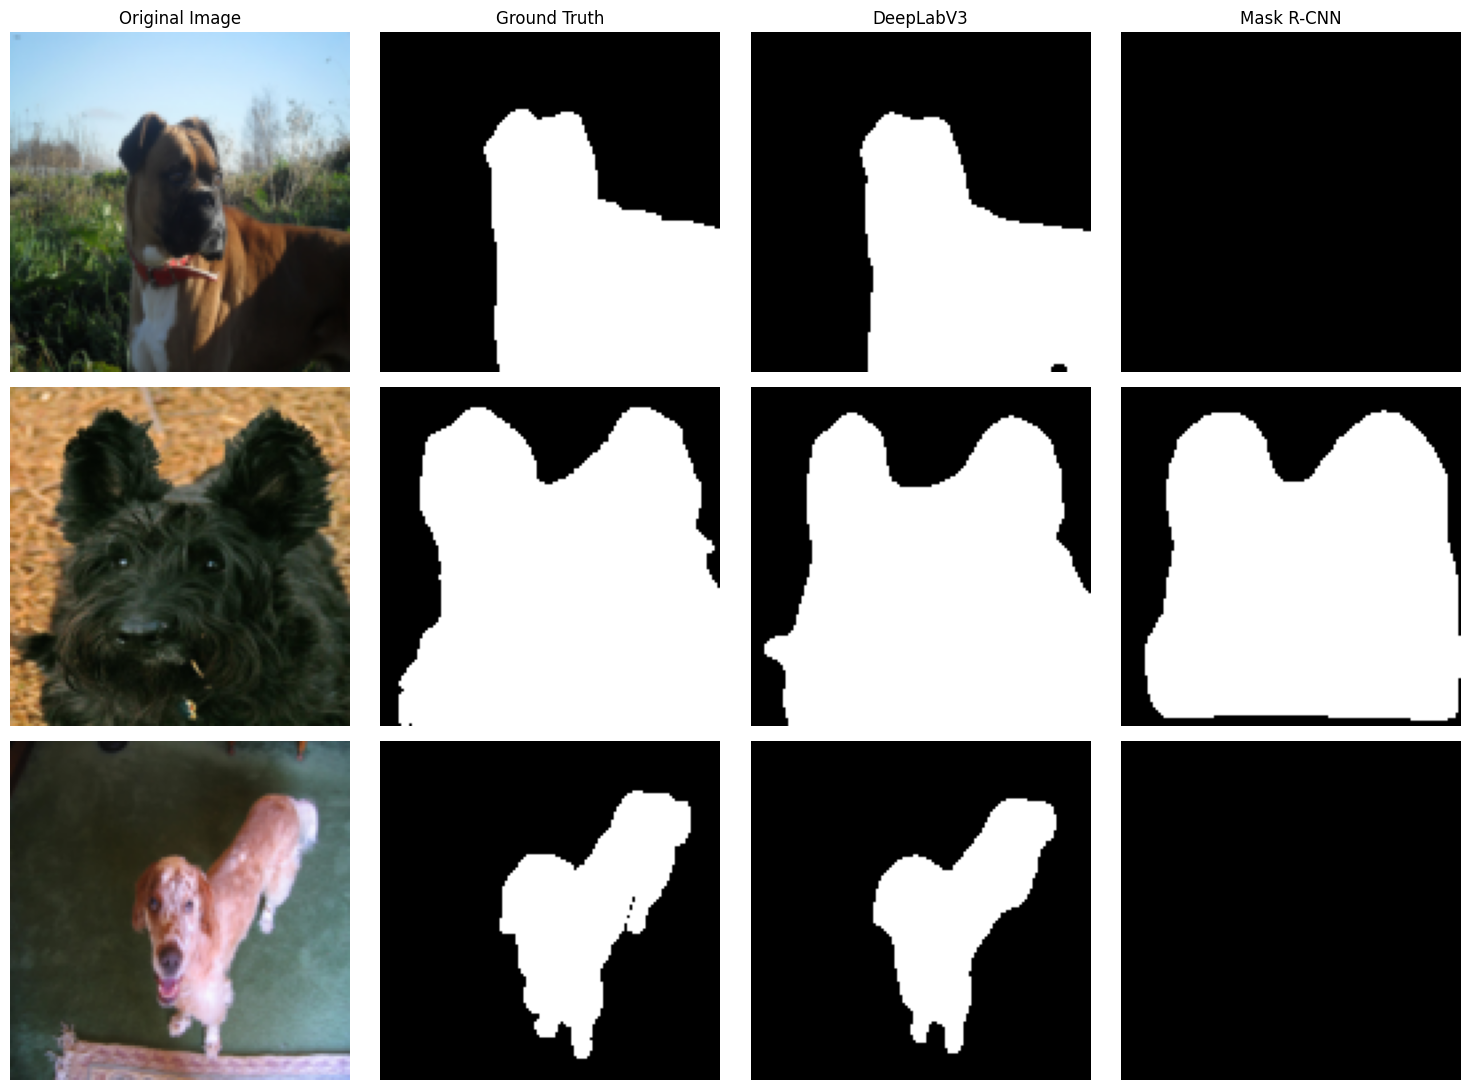

In [16]:
fig, axes = plt.subplots(3, 4, figsize=(15, 11))

for i in range(3):

    image, true_mask = pet_test_dataset[i]

    panels = [
        image.permute(1, 2, 0).numpy(),
        true_mask.squeeze().numpy(),
        deeplab_predictions[i],
        maskrcnn_predictions[i]
    ]

    titles = [
        "Original Image",
        "Ground Truth",
        "DeepLabV3",
        "Mask R-CNN"
    ]

    for j in range(4):

        if j == 0:
            axes[i, j].imshow(panels[j])
        else:
            axes[i, j].imshow(
                panels[j],
                cmap="gray",
                vmin=0,
                vmax=1
            )

        if i == 0:
            axes[i, j].set_title(titles[j])

        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [17]:
save_dir = "/content/tutorial11_results"
os.makedirs(save_dir, exist_ok=True)

deeplab_df.to_csv(
    f"{save_dir}/deeplab_test_results.csv",
    index=False
)

maskrcnn_df.to_csv(
    f"{save_dir}/maskrcnn_test_results.csv",
    index=False
)

comparison.to_csv(
    f"{save_dir}/model_comparison.csv",
    index=False
)

print("Tutorial 11 results saved.")

Tutorial 11 results saved.


## Analysis

DeepLabV3 achieved better segmentation performance than Mask R-CNN on the selected test dataset.

DeepLabV3 obtained a Dice score of 86.54% and IoU of 80.18%, compared with 80.09% and 74.53%, respectively, for Mask R-CNN.

Visual inspection showed that DeepLabV3 generally produced segmentation masks that closely matched the ground-truth pet silhouettes.

Mask R-CNN produced accurate masks in some examples but failed to retain a valid cat or dog detection in others, resulting in empty segmentation masks.

This difference can be partially attributed to the models' prediction strategies. DeepLabV3 predicts semantic classes directly for every pixel, whereas Mask R-CNN first detects object instances and then predicts masks for those detections. The confidence threshold can therefore affect Mask R-CNN's final segmentation coverage.

The experiment compares pretrained inference performance only and does not establish that one architecture is universally superior.